# Superstore Sales Data Analysis

## 1. Project Overview

This project analyzes Superstore sales data to identify sales trends, evaluate product performance, understand regional profitability, and explore the relationship between discounts and profit

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Data Loading and Initial Inspection

Load the dataset and examine its structure, dimensions, column names, data types, and summary statistics.

In [7]:
#LOADING CSV FILE

df = pd.read_csv("Sample-Superstore.csv")

In [8]:
#TOP 5 ROWS OF DATAFRAME

print(df.head(5))

   csvbase_row_id  ﻿Row ID        Order ID  Order Date   Ship Date  \
0               1        1  CA-2016-152156  2016-11-08  2016-11-11   
1               2        2  CA-2016-152156  2016-11-08  2016-11-11   
2               3        3  CA-2016-138688  2016-06-12  2016-06-16   
3               4        4  US-2015-108966  2015-10-11  2015-10-18   
4               5        5  US-2015-108966  2015-10-11  2015-10-18   

        Ship Mode Customer ID    Customer Name    Segment        Country  ...  \
0    Second Class    CG-12520      Claire Gute   Consumer  United States  ...   
1    Second Class    CG-12520      Claire Gute   Consumer  United States  ...   
2    Second Class    DV-13045  Darrin Van Huff  Corporate  United States  ...   
3  Standard Class    SO-20335   Sean O'Donnell   Consumer  United States  ...   
4  Standard Class    SO-20335   Sean O'Donnell   Consumer  United States  ...   

  Postal Code Region       Product ID         Category Sub-Category  \
0       42420  South 

In [9]:
#LAST 5 ROWS OF DATAFRAME

print(df.tail(5))

      csvbase_row_id  ﻿Row ID        Order ID  Order Date   Ship Date  \
9989            9990     9990  CA-2014-110422  2014-01-21  2014-01-23   
9990            9991     9991  CA-2017-121258  2017-02-26  2017-03-03   
9991            9992     9992  CA-2017-121258  2017-02-26  2017-03-03   
9992            9993     9993  CA-2017-121258  2017-02-26  2017-03-03   
9993            9994     9994  CA-2017-119914  2017-05-04  2017-05-09   

           Ship Mode Customer ID     Customer Name   Segment        Country  \
9989    Second Class    TB-21400  Tom Boeckenhauer  Consumer  United States   
9990  Standard Class    DB-13060       Dave Brooks  Consumer  United States   
9991  Standard Class    DB-13060       Dave Brooks  Consumer  United States   
9992  Standard Class    DB-13060       Dave Brooks  Consumer  United States   
9993    Second Class    CC-12220      Chris Cortes  Consumer  United States   

      ... Postal Code Region       Product ID         Category Sub-Category  \
9989  .

In [10]:
#FINDING THE SHAPE OF DATAFRAME

df.shape

(9994, 22)

In [11]:
#ALL COLUMNS NAME FORM DATA FRAME

df.columns

Index(['csvbase_row_id', '﻿Row ID', 'Order ID', 'Order Date', 'Ship Date',
       'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country',
       'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [12]:
#ALL INFROMATION ABOUT EACH COLUMN

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   csvbase_row_id  9994 non-null   int64  
 1   ﻿Row ID         9994 non-null   int64  
 2   Order ID        9994 non-null   object 
 3   Order Date      9994 non-null   object 
 4   Ship Date       9994 non-null   object 
 5   Ship Mode       9994 non-null   object 
 6   Customer ID     9994 non-null   object 
 7   Customer Name   9994 non-null   object 
 8   Segment         9994 non-null   object 
 9   Country         9994 non-null   object 
 10  City            9994 non-null   object 
 11  State           9994 non-null   object 
 12  Postal Code     9994 non-null   int64  
 13  Region          9994 non-null   object 
 14  Product ID      9994 non-null   object 
 15  Category        9994 non-null   object 
 16  Sub-Category    9994 non-null   object 
 17  Product Name    9994 non-null   o

In [13]:
#SUMMARY

print(df.describe())

       csvbase_row_id      ﻿Row ID   Postal Code         Sales     Quantity  \
count     9994.000000  9994.000000   9994.000000   9994.000000  9994.000000   
mean      4997.500000  4997.500000  55190.379428    229.858001     3.789574   
std       2885.163629  2885.163629  32063.693350    623.245101     2.225110   
min          1.000000     1.000000   1040.000000      0.444000     1.000000   
25%       2499.250000  2499.250000  23223.000000     17.280000     2.000000   
50%       4997.500000  4997.500000  56430.500000     54.490000     3.000000   
75%       7495.750000  7495.750000  90008.000000    209.940000     5.000000   
max       9994.000000  9994.000000  99301.000000  22638.480000    14.000000   

          Discount       Profit  
count  9994.000000  9994.000000  
mean      0.156203    28.656896  
std       0.206452   234.260108  
min       0.000000 -6599.978000  
25%       0.000000     1.728750  
50%       0.200000     8.666500  
75%       0.200000    29.364000  
max       0.8000

## 3. Data Cleaning and Quality Checks

Identify missing values, duplicate records, inconsistent column names, and incorrect data types. Validate categorical values and check for potential data quality issues.

In [14]:
#ALL COLUMNS NAME FORM DATA FRAME

df.columns

Index(['csvbase_row_id', '﻿Row ID', 'Order ID', 'Order Date', 'Ship Date',
       'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country',
       'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [15]:
#REMOVED COLUMN NAMED csvbase_row_id 

df = df.drop('csvbase_row_id',axis=1)

In [16]:
#CHECKING SPACE AND REMOVING FROM COLUMNS

df.columns = df.columns.str.strip()
df.columns

Index(['﻿Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [17]:
#FINDING NULL VALUE COUNT FROM EACH COLUMN

print(df.isnull().sum())

﻿Row ID          0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [18]:
#MISSING VALUE PERCENTAGE

print(df.isna().sum() / len(df)*100)

﻿Row ID          0.0
Order ID         0.0
Order Date       0.0
Ship Date        0.0
Ship Mode        0.0
Customer ID      0.0
Customer Name    0.0
Segment          0.0
Country          0.0
City             0.0
State            0.0
Postal Code      0.0
Region           0.0
Product ID       0.0
Category         0.0
Sub-Category     0.0
Product Name     0.0
Sales            0.0
Quantity         0.0
Discount         0.0
Profit           0.0
dtype: float64


In [19]:
#FINDING THE TOTAL OF DUPLICATED ROWS FROM THE DATADFRAME

print(df.duplicated().sum())

0


In [20]:
#COLUMNS DATA TYPE

print(df.dtypes)

﻿Row ID            int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [21]:
#FINDING UNIQUE VALUES FROM DATAFAME FOR EACH COLUMN

print(df.nunique())

﻿Row ID          9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64


## 4. Feature Engineering

Create additional features, including shipping duration, profit status, profit margin, and shipping categories, to support further analysis.

In [22]:
#RECHECKING THE COLUMNS AND CORECTING THE SPACE AND STANDARDIZATION
#DROPNA=FALSE HELP TO COUNT N/A VALUES ALSO

df.columns
df['Ship Mode'].value_counts(dropna=False)
df['Category'].value_counts(dropna=False)
df['Region'].value_counts(dropna=False)

Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

In [23]:
#CORRECTED THE REGION 'south' --> 'South'

df['Region'] = df['Region'].replace('south','South')

In [24]:
#DATA TYPE CHECKING OF ORDER COLUMNS

print(df[['Order Date','Ship Date']].dtypes)

Order Date    object
Ship Date     object
dtype: object


In [25]:
#CONVERTING OBJECT COLUMN TO DATETIME FOR ERROR FREE CALCULATION

df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [26]:
#NOW FINDING THE SHIPPING DAYS FROM DIFFRENCE

df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

In [27]:
#CHECKING AFTER CONVERTING 

print(df[['Order Date','Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [28]:
#DATAFAME DESCRIPTIVE STATS

print(df[['Sales','Quantity','Discount','Profit']].describe())

              Sales     Quantity     Discount       Profit
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001     3.789574     0.156203    28.656896
std      623.245101     2.225110     0.206452   234.260108
min        0.444000     1.000000     0.000000 -6599.978000
25%       17.280000     2.000000     0.000000     1.728750
50%       54.490000     3.000000     0.200000     8.666500
75%      209.940000     5.000000     0.200000    29.364000
max    22638.480000    14.000000     0.800000  8399.976000


In [29]:
#USING APPLY() FOR CHECKING PROFIT STATUS OF BUSINESS

def check(x):
    if x > 0:
        return 'Profit'
    elif x < 0:
        return 'Loss'
    else:
        return 'Break Even'

#APPLY THE APPLY() ON PROFIT COLUMN
df['Profit Status'] = df['Profit'].apply(check)

#WE CAN CHECK PROFIT STATUS NAMED COLUMN IS ADDED TO DATA FRAME\
df['Profit Status'].head(5)

0    Profit
1    Profit
2    Profit
3      Loss
4    Profit
Name: Profit Status, dtype: object

In [30]:
#USING MAP() FOR CREATING NEW COLUMNS TO CATEGORIZE SHIP MODE

#DEFINING FOR MAP() METHOD
new = {
    'Standard Class':'Standard',
    'Second Class' : 'Second',
    'First Class' : 'First',
    'Same Day' : 'Express'
}


#ALL TYPE SHIP MODE
print(df['Ship Mode'].value_counts())

#APPLY MAP() FOR NEW COLUMN
df['Shipping Categorized'] = df['Ship Mode'].map(new)

print('\n')

print(df['Shipping Categorized'].head(5))

Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64


0      Second
1      Second
2      Second
3    Standard
4    Standard
Name: Shipping Categorized, dtype: object


## 5. Exploratory Data Analysis (EDA)

### 5.1 Product Performance Analysis

In [31]:
#TOP PRODUCTS GIVING HIGHEST PROFIT BY INDIVIDUALY

print(df.sort_values(by='Profit',ascending=False)[['Product Name','Sales','Profit']].head(5))

                                          Product Name     Sales     Profit
6826             Canon imageCLASS 2200 Advanced Copier  17499.95  8399.9760
8153             Canon imageCLASS 2200 Advanced Copier  13999.96  6719.9808
4190             Canon imageCLASS 2200 Advanced Copier  10499.97  5039.9856
9039  GBC Ibimaster 500 Manual ProClick Binding System   9892.74  4946.3700
4098              Ibico EPK-21 Electric Binding System   9449.95  4630.4755


In [32]:
#TOP 5 PRODUCT WITH HIGHEST SALES

print(df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(5))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
Name: Sales, dtype: float64


In [33]:
#TOP 5 PRODUCTS WITH LOWEST SALES

print(df.groupby('Product Name')['Sales'].sum().sort_values(ascending=True).head(5))

Product Name
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Avery 5                                                             5.760
Xerox 20                                                            6.480
Grip Seal Envelopes                                                 7.072
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                  7.700
Name: Sales, dtype: float64


### 5.2 Category and Sub-Category Analysis

In [34]:
#GROUPBY WITH CATEGORY SHOWING MEAN AND SUM

category = df.groupby('Category')['Sales'].sum()
print(category)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


In [35]:
#SUB-CATEGORY ANALYSE WITH DIFFRENCE BETWEEN SALES AND PROFIT

print(df.groupby('Sub-Category').agg({'Sales':['sum'],'Profit':['sum','mean']}))

                    Sales      Profit            
                      sum         sum        mean
Sub-Category                                     
Accessories   167380.3180  41936.6357   54.111788
Appliances    107532.1610  18138.0054   38.922758
Art            27118.7920   6527.7870    8.200737
Binders       203412.7330  30221.7633   19.843574
Bookcases     114879.9963  -3472.5560  -15.230509
Chairs        328449.1030  26590.1663   43.095894
Copiers       149528.0300  55617.8249  817.909190
Envelopes      16476.4020   6964.1767   27.418019
Fasteners       3024.2800    949.5182    4.375660
Furnishings    91705.1640  13059.1436   13.645918
Labels         12486.3120   5546.2540   15.236962
Machines      189238.6310   3384.7569   29.432669
Paper          78479.2060  34053.5693   24.856620
Phones        330007.0540  44515.7306   50.073938
Storage       223843.6080  21278.8264   25.152277
Supplies       46673.5380  -1189.0995   -6.258418
Tables        206965.5320 -17725.4811  -55.565771


In [36]:
#TOP 5 MOST PROFITABLE SUB-CATEGORY

df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False).head(5)

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Name: Profit, dtype: float64

In [37]:
#TOP 5 LOSS MAKING SUB-CATEGORIES

df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=True).head(5)

Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64

### 5.3 Regional Sales and Profit Analysis

In [38]:
#GROUPBY BY REGION SALLES

print(df.groupby('Region').agg({'Sales':['sum'],'Profit':['sum']}))

               Sales       Profit
                 sum          sum
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


In [39]:
#REGION WISE PROFT MARGINE

region_profit = df.groupby('Region')[['Sales', 'Profit']].sum()
region_profit['Profit Margin'] = (region_profit['Profit'] / region_profit['Sales']) * 100
region_profit

,Sales,Profit,Profit Margin
Region,,,
Central,501239.8908,39706.3625,7.921629
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
West,725457.8245,108418.4489,14.944831


### 5.4 Shipping Mode Analysis

In [40]:
#PERCENTAGE SHIPING MODES IN DATA FRAME  

print(df['Ship Mode'].value_counts(normalize=True)*100)

Ship Mode
Standard Class    59.715829
Second Class      19.461677
First Class       15.389234
Same Day           5.433260
Name: proportion, dtype: float64


In [41]:
#TOTAL SALES REGIONS WISE BY SHOWING SHIP MODE 

pd.pivot_table(df,index='Region',columns='Ship Mode',values='Sales',aggfunc='sum')

Ship Mode,First Class,Same Day,Second Class,Standard Class
Region,,,,
Central,58746.9154,20415.410,103550.0054,318527.5600
East,113587.0530,43326.832,116545.5240,405321.8310
South,49332.5660,21017.173,93758.6125,227613.5535
West,129761.8885,43603.710,145339.4275,406752.7985


In [42]:
#SHIPPING MODE PROFIT ANALYSE

print(df.groupby('Ship Mode').agg({'Profit':['sum','mean']}))

                     Profit           
                        sum       mean
Ship Mode                             
First Class      48969.8399  31.839948
Same Day         15891.7589  29.266591
Second Class     57446.6354  29.535545
Standard Class  164088.7875  27.494770


In [43]:
# COUNT OF SHIPING MODE USED REGION WISE

pd.crosstab(df['Ship Mode'],df['Region'])

Region,Central,East,South,West
Ship Mode,,,,
First Class,299,490,234,515
Same Day,120,155,83,185
Second Class,465,530,329,621
Standard Class,1439,1673,974,1882


### 5.5 Discount and Profit Relationship

In [44]:
# ANALYZING THE CORRELATION BETWEEN DISCOUNT AND PROFIT

print(df['Profit'].corr(df['Discount']))

-0.21948745637176809


In [45]:
# ANALYZING THE COVARIANCE BETWEEN DISCOUNT AND PROFIT

print(df['Profit'].cov(df['Discount']))

-10.615172864116834


### 5.6 Monthly and Yearly Sales Trends

In [46]:
## ANALYZING MONTHLY SALES TRENDS TO TRACK SALES PERFORMANCE OVER TIME

monthly_sales = df.set_index('Order Date')['Sales'].resample('ME').sum()
print(monthly_sales)

Order Date
2014-01-31     14236.8950
2014-02-28      4519.8920
2014-03-31     55691.0090
2014-04-30     28295.3450
2014-05-31     23648.2870
2014-06-30     34595.1276
2014-07-31     33946.3930
2014-08-31     27909.4685
2014-09-30     81777.3508
2014-10-31     31453.3930
2014-11-30     78628.7167
2014-12-31     69545.6205
2015-01-31     18174.0756
2015-02-28     11951.4110
2015-03-31     38726.2520
2015-04-30     34195.2085
2015-05-31     30131.6865
2015-06-30     24797.2920
2015-07-31     28765.3250
2015-08-31     36898.3322
2015-09-30     64595.9180
2015-10-31     31404.9235
2015-11-30     75972.5635
2015-12-31     74919.5212
2016-01-31     18542.4910
2016-02-29     22978.8150
2016-03-31     51715.8750
2016-04-30     38750.0390
2016-05-31     56987.7280
2016-06-30     40344.5340
2016-07-31     39261.9630
2016-08-31     31115.3743
2016-09-30     73410.0249
2016-10-31     59687.7450
2016-11-30     79411.9658
2016-12-31     96999.0430
2017-01-31     43971.3740
2017-02-28     20301.1334
2

In [47]:
#ANALYZING YEARLY SALES TRENDS TO COMPARE ANNUAL SALES PERFORMANCE

yearly_sales = df.set_index('Order Date')['Sales'].resample('YE').sum()
print(yearly_sales)

Order Date
2014-12-31    484247.4981
2015-12-31    470532.5090
2016-12-31    609205.5980
2017-12-31    733215.2552
Freq: YE-DEC, Name: Sales, dtype: float64


# 6. Data Visualization

In this section, I will use Matplotlib and Seaborn to visualize sales, profit, shipping, and discount-related patterns in the Superstore dataset. Visualizations will help identify trends, compare business performance, and communicate key insights clearly.

## 6.1 Monthly Sales Trend

A line chart will be used to analyze monthly sales over time and identify sales trends, peaks, and declines.

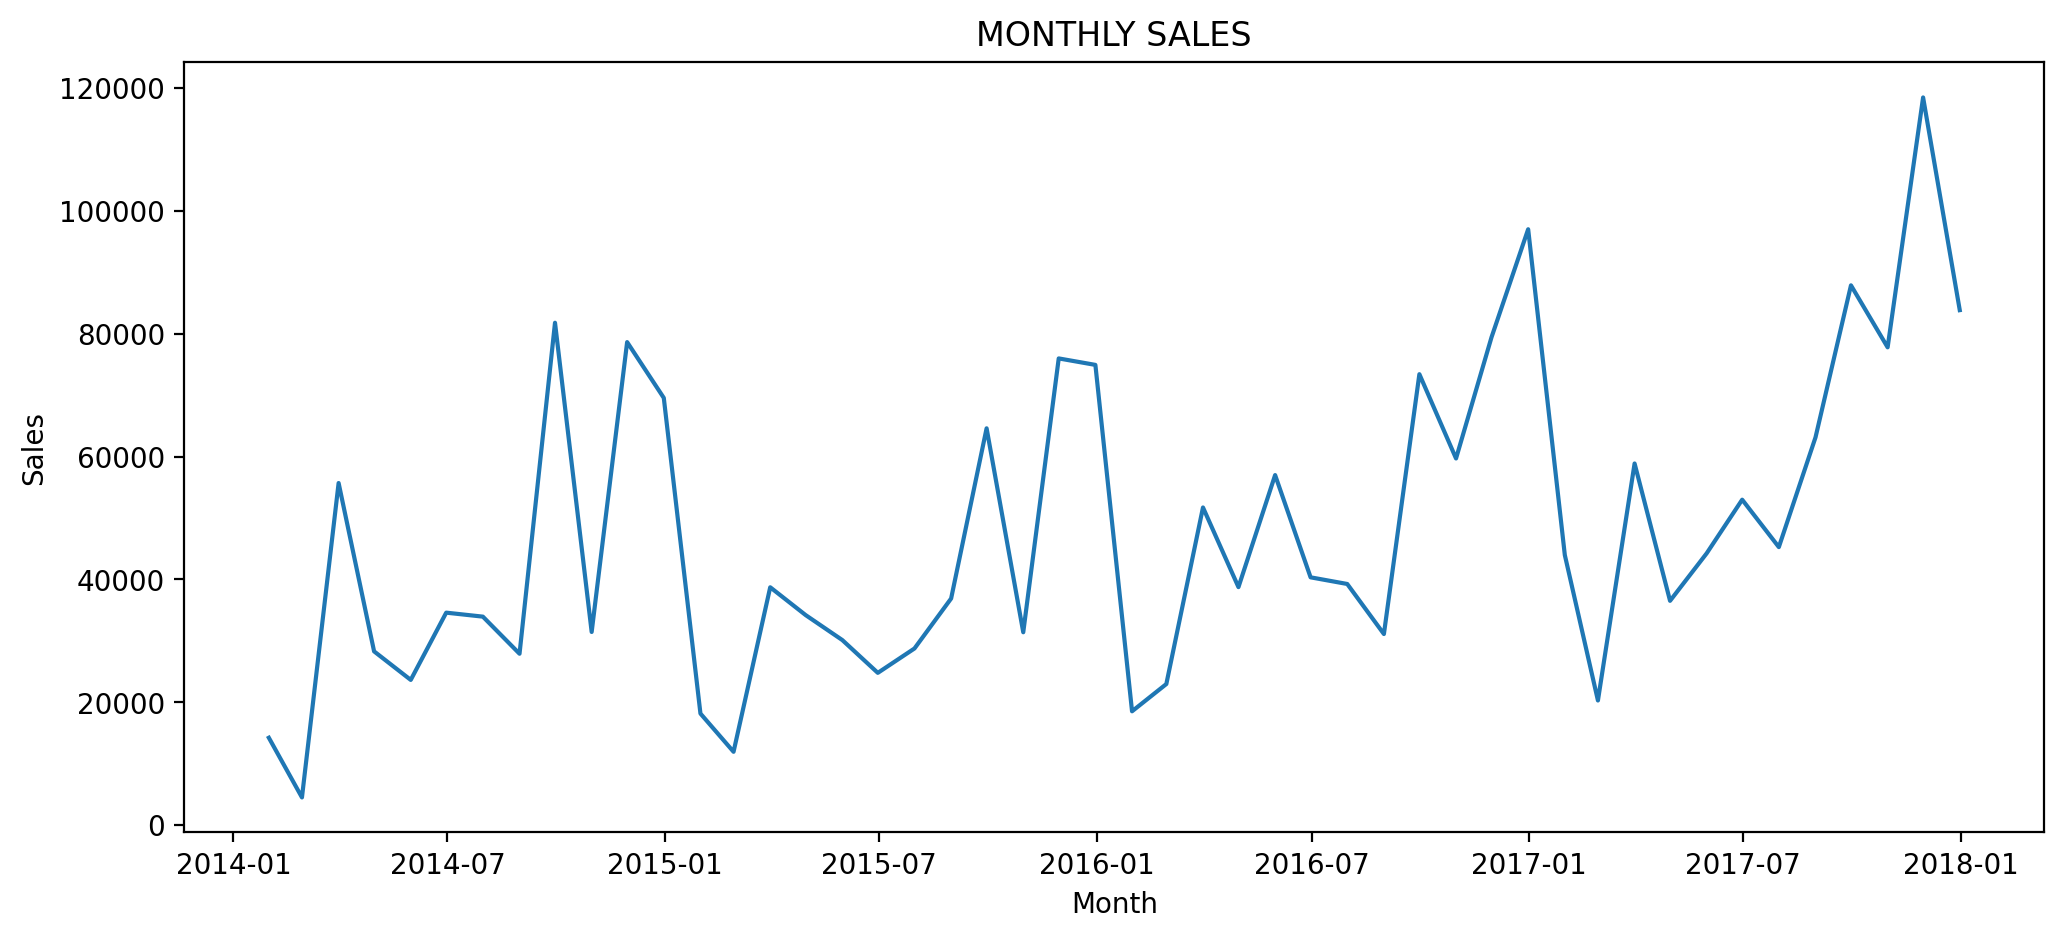

In [48]:
plt.figure(figsize=(12,5),dpi=200)
plt.title('MONTHLY SALES')
plt.xlabel('Month')
plt.ylabel('Sales')
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values)
plt.show()

### Key Insight
Monthly sales show a lot of variation over time. Some months have much higher sales than others, and the overall trend is not consistent every month. Sales appear relatively high towards the end of the dataset.

### Business Recommendation
It would be useful to compare sales across the same months in different years to understand whether seasonal patterns exist. This can help with inventory and sales planning.


## 6.2 Sales by Category

A bar chart will be used to compare total sales across different product categories and identify the highest-performing category.

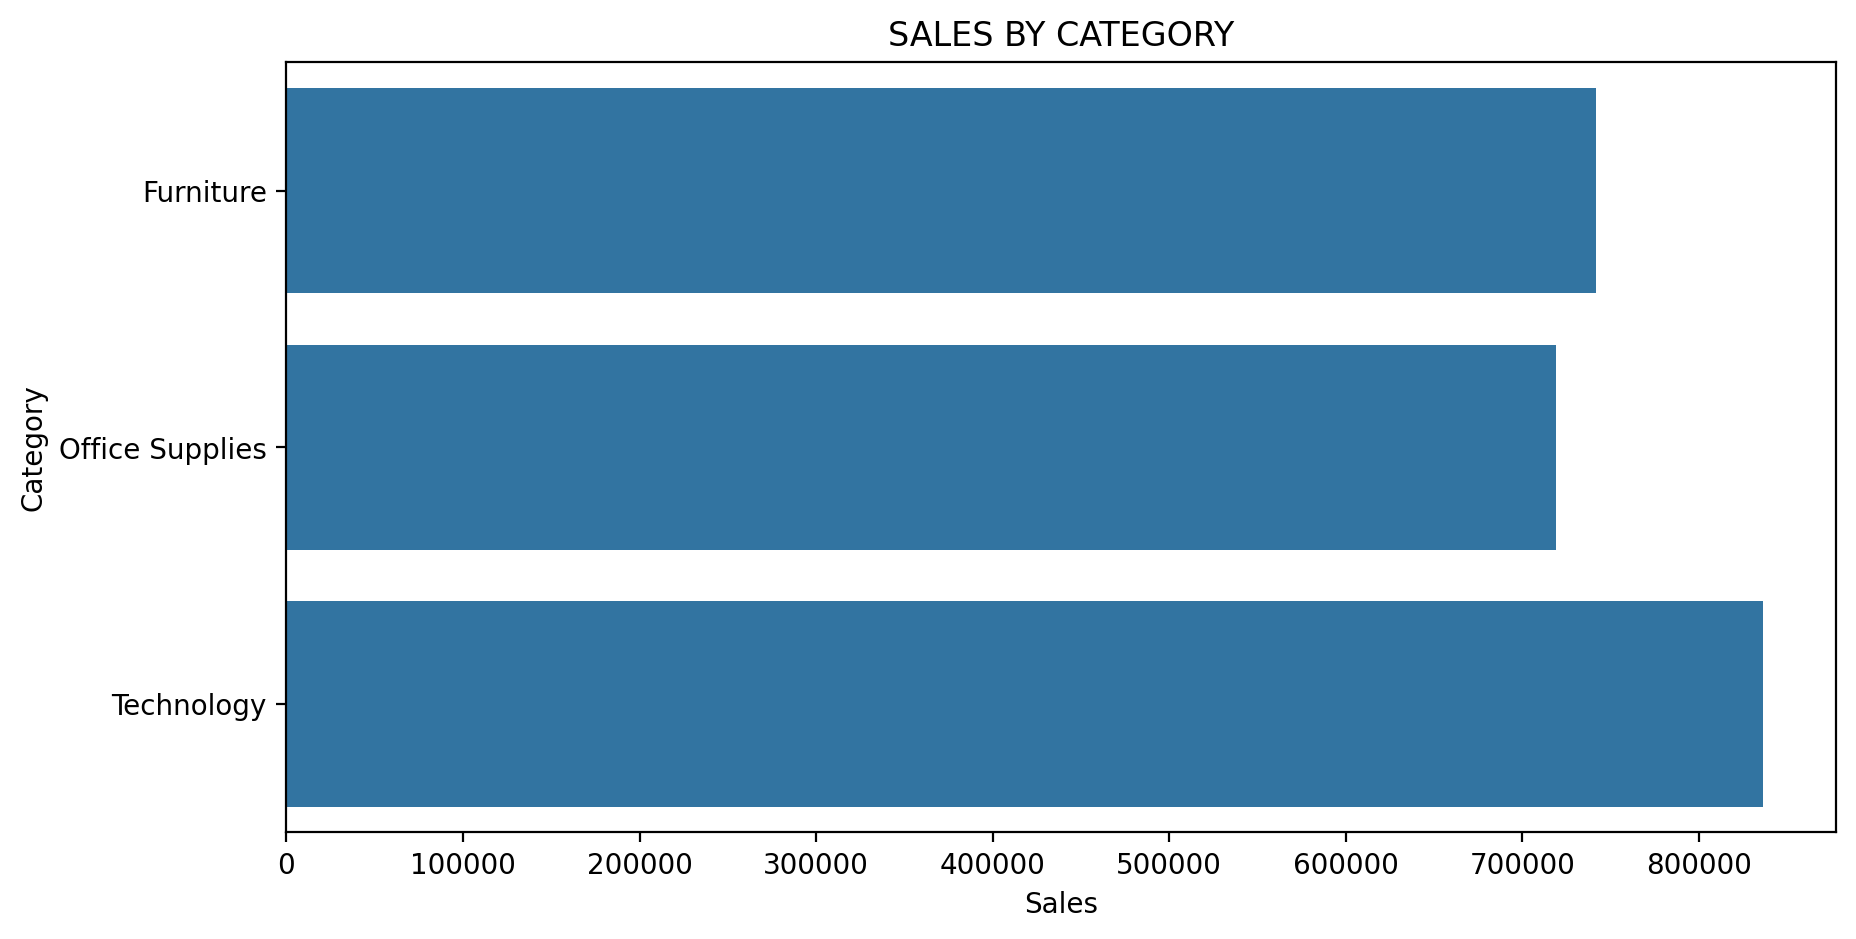

In [49]:
plt.figure(figsize=(10,5),dpi=200)
plt.title('SALES BY CATEGORY')
plt.xlabel('Sales')
sns.barplot(x=category.values,y=category.index)
plt.show()

### Key Insight
Technology has the highest total sales among the three categories, followed by Furniture and Office Supplies. This shows that Technology contributes the most to overall sales in this dataset.

### Business Recommendation
The business can look more closely at the products driving Technology sales and identify opportunities to improve sales in Office Supplies. Category-wise profit should also be checked before making decisions based only on sales.


## 6.3 Profit by Region

A bar chart will be used to compare total profit across regions and identify the regions contributing the most and least profit.

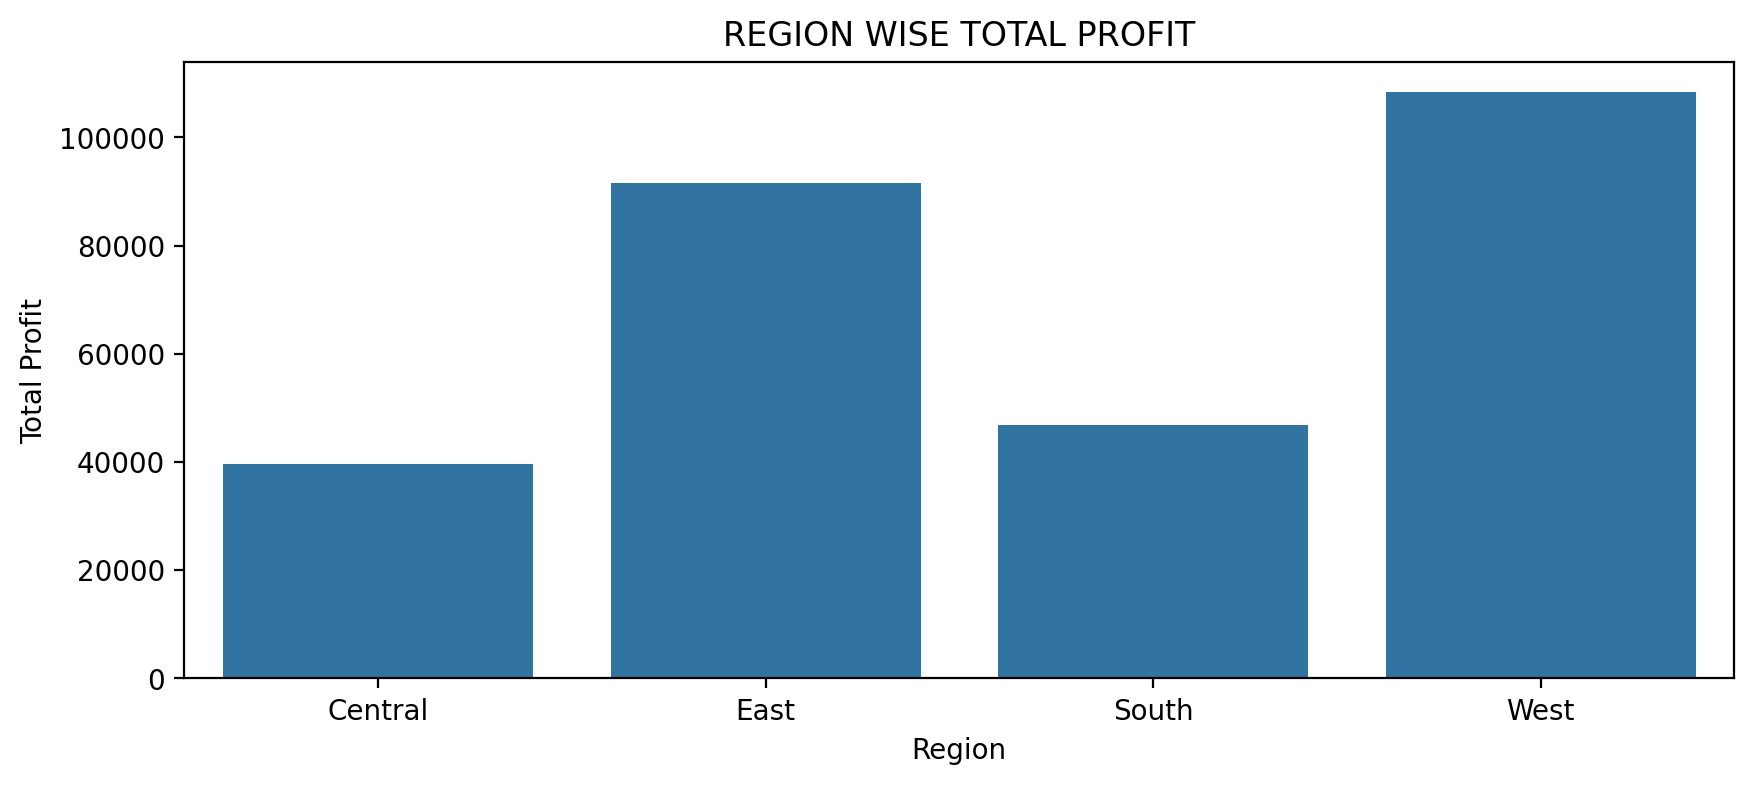

In [50]:
total_profit = df.groupby('Region')['Profit'].sum()

plt.figure(figsize=(10,4),dpi=200)
plt.title('REGION WISE TOTAL PROFIT')
plt.ylabel('Total Profit')
sns.barplot(x=total_profit.index,y=total_profit.values)
plt.show()

### Key Insight
The West region generates the highest total profit, followed by East. South and Central generate noticeably less profit, with Central having the lowest total.

### Business Recommendation
The business should investigate product-level sales, discounts and profit in Central and South to understand what is limiting their performance. Comparing profit margins across regions would also give a clearer picture.

# 6.4 Order Distribution by Ship Mode

A pie chart is used to analyze the percentage contribution of each shipping mode to the total number of orders. This visualization helps identify the most frequently used shipping mode and compare customer shipping preferences across different options.

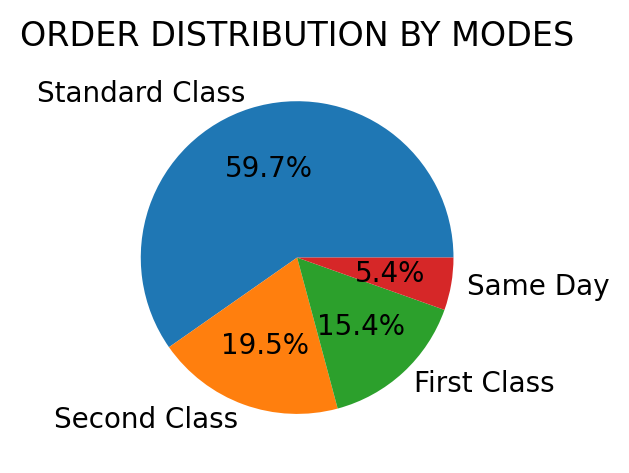

In [51]:

ship_mode = df['Ship Mode'].value_counts()
plt.figure(figsize=(3,4),dpi=200)
plt.pie(ship_mode.values,labels=ship_mode.index,autopct='%1.1f%%')
plt.title('ORDER DISTRIBUTION BY MODES')
plt.tight_layout()
plt.show()

### Key Insight
Standard Class accounts for around 59.7% of orders, making it the most commonly used shipping mode. Same Day accounts for only 5.4%, so it is the least used option in this dataset.

### Business Recommendation
Since most orders use Standard Class, the business should make sure this shipping option is handled efficiently. Shipping costs and delivery times can be reviewed to understand whether the current mix is working well.

## 6.5 Discount vs Profit Relationship

A scatter plot will be used to explore the relationship between discount levels and profit and identify patterns that may indicate how discounts affect profitability.

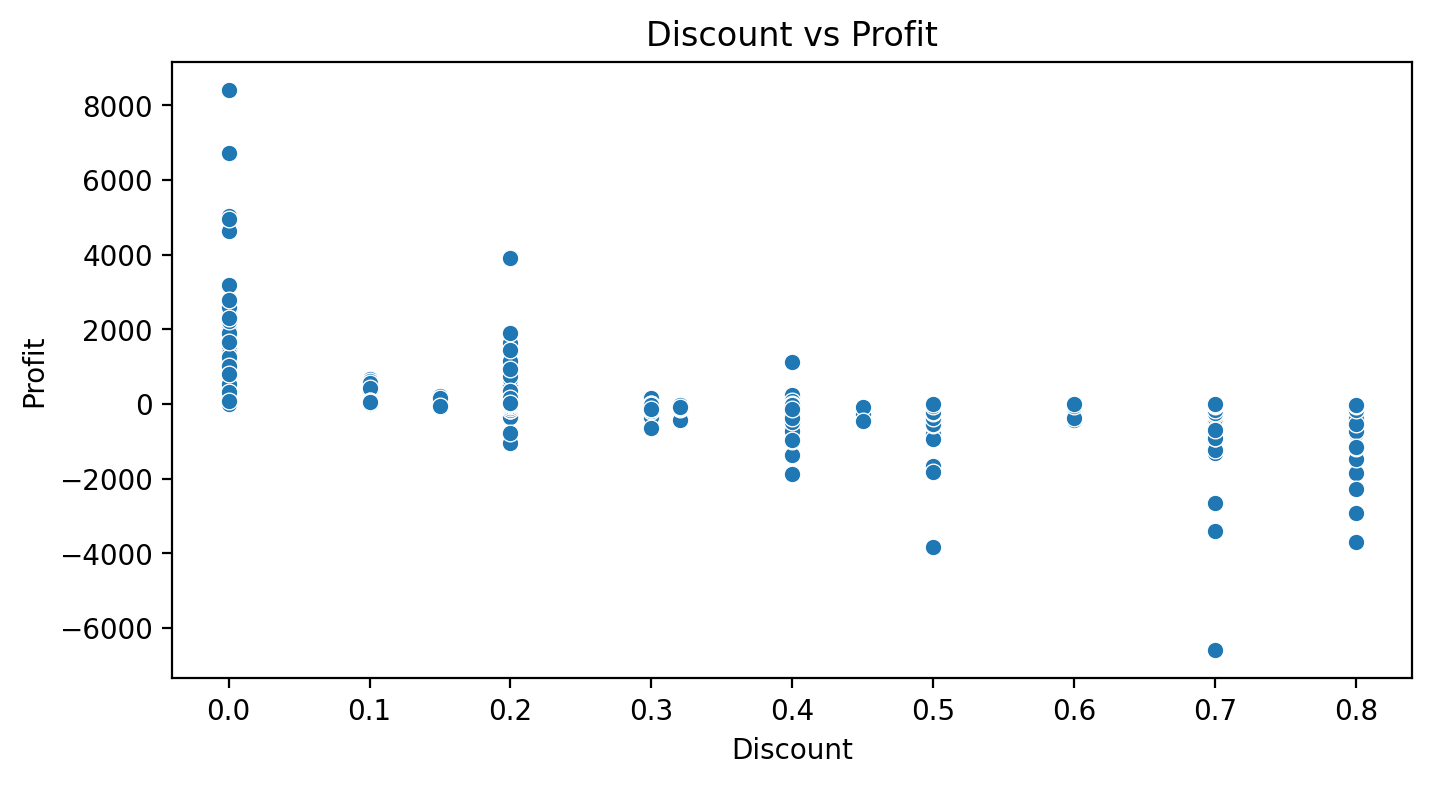

In [52]:
plt.figure(figsize=(8,4),dpi=200)
plt.title('Discount vs Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')

sns.scatterplot(data=df ,x='Discount',y='Profit')
plt.show()

### Key Insight
The scatter plot shows that many orders with higher discounts have negative profit, especially at discount levels of 50% and above. However, profit also varies at lower discount levels, so discounts may not be the only factor affecting profitability.

### Business Recommendation
The business should review high-discount orders by product and category to identify where discounts may be reducing profit. Product costs and sales volume should also be considered before changing the discount policy.

# Overall Business Conclusion

The analysis of the Superstore dataset highlights a few important patterns in sales, profit and shipping. Technology has the highest total sales among the product categories, while the West region contributes the highest total profit. Standard Class is the most commonly used shipping mode, accounting for around 59.7% of orders.

The discount analysis also shows that several orders with higher discounts result in losses. This suggests that discount levels should be reviewed carefully, although other factors such as product costs and category performance may also affect profit.

Overall, the business can use these findings to review regional performance, understand product-level profitability and make better decisions about discounts and shipping. Further analysis of profit margins and product-level results would help support these decisions.

In [53]:
import os
print(os.getcwd())

C:\Users\choud\PANDAS PROJECT -1
